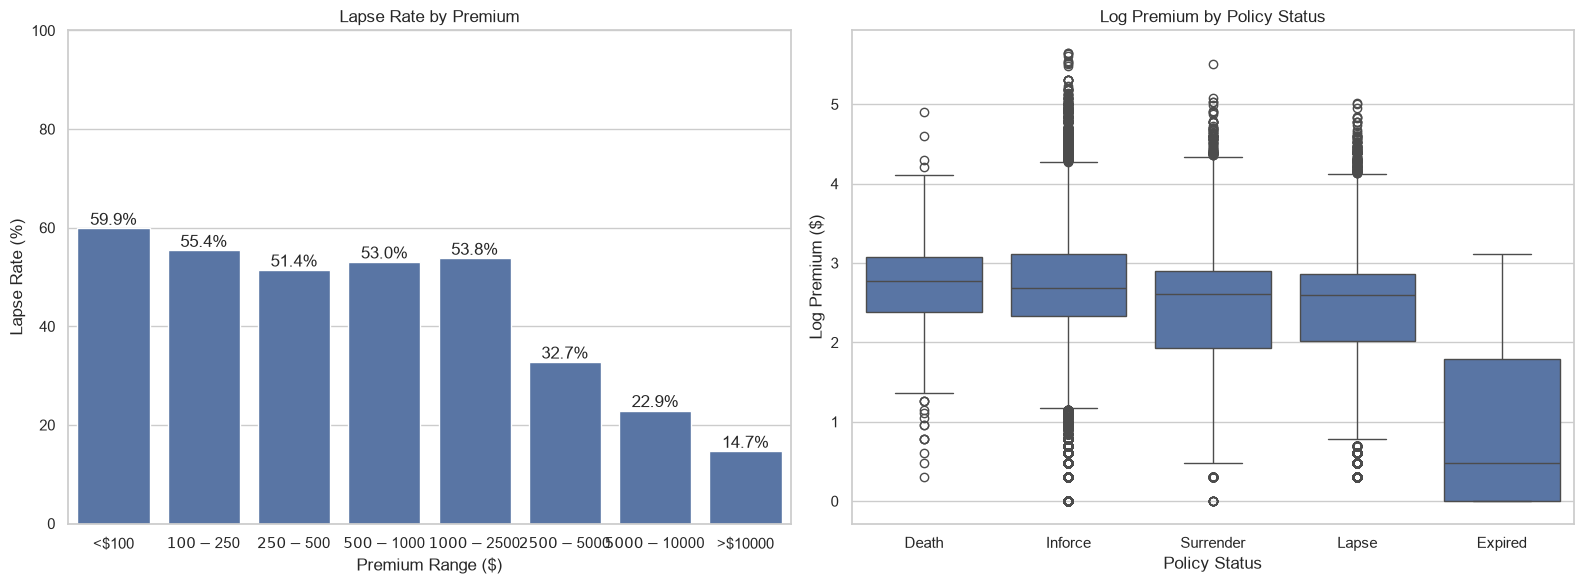

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("data/CleanedLifeInsurance.csv")

df_premium = df.dropna(subset = ['Premium']).copy()

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bins = [0, 100, 250, 500, 1000, 2500, 5000, 10000, np.inf]
labels = [
    '<$100',
    '$100-$250',
    '$250-$500',
    '$500-$1000',
    '$1000-$2500',
    '$2500-$5000',
    '$5000-$10000',
    '>$10000'
]

df_premium['Premium_Range'] = pd.cut(df_premium['Premium'], bins = bins, labels = labels)

lapse_rates = (df_premium.groupby('Premium_Range', observed = False)['is_lapse'].mean().reset_index())
lapse_rates['Lapse_Rate_Pct'] = lapse_rates['is_lapse'] * 100

sns.barplot(data = lapse_rates,
            x = 'Premium_Range',
            y = 'Lapse_Rate_Pct',
            ax = axes[0],
            )
axes[0].set_title('Lapse Rate by Premium')
axes[0].set_xlabel('Premium Range ($)')
axes[0].set_ylabel('Lapse Rate (%)')
axes[0].set_ylim(0, 100)

for p in axes[0].patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        axes[0].annotate(
            f'{height:.1f}%',
            (p.get_x() + p.get_width() / 2.0, height),
            ha = 'center',
            va = 'bottom'
        )

df_premium['Log_Premium'] = np.log10(df_premium['Premium'])

status_order = (
    df_premium.groupby('POLICY STATUS')['Log_Premium']
    .median()
    .sort_values(ascending = False)
    .index
)

sns.boxplot(
    data = df_premium,
    x = 'POLICY STATUS',
    y = 'Log_Premium',
    order = status_order,
    ax = axes[1]
)
axes[1].set_title('Log Premium by Policy Status')
axes[1].set_xlabel('Policy Status')
axes[1].set_ylabel('Log Premium ($)')

plt.tight_layout()
plt.show()